# Notebook 03 — Componente supervisado: predecir si la sesión termina en compra

**Problema:** clasificación binaria con **desbalance** (~15,6 % de compras). **Objetivo:** estimar la probabilidad de compra de una sesión y decidir cuándo intervenir.

**Diseño experimental (sin fuga de información):**
1. División estratificada 80/20 fijada en `src/preprocesamiento.py`; **el test no se toca hasta el final**.
2. Todo el preprocesamiento va **dentro de un `Pipeline`**, así en cada pliegue de validación cruzada el escalado y la codificación se ajustan solo con los datos de entrenamiento de ese pliegue.
3. Los modelos se **comparan con validación cruzada estratificada de 5 pliegues sobre train**; la selección de hiperparámetros y del **umbral de decisión** también se hace solo con train.
4. El test se usa **una sola vez**, para reportar el desempeño final del modelo elegido.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas del proyecto (los notebooks viven en evaluacion 4/notebooks)
RAIZ = Path('..').resolve()
DATOS = RAIZ / 'data' / 'online_shoppers_intention.csv'
FIG = RAIZ / 'figuras'
RES = RAIZ / 'resultados'
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE, ROJO = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A', '#C0392B'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

sys.path.insert(0, str(RAIZ / 'src'))
from preprocesamiento import (cargar_datos, dividir_train_test, construir_preprocesador, matriz_conducta,
                              NUMERICAS, CATEGORICAS, BINARIAS, CONDUCTA, OBJETIVO, SEMILLA, MESES_ORDEN)

In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix)

df = cargar_datos()
X_train, X_test, y_train, y_test = dividir_train_test(df)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f'train: {len(X_train):,} sesiones ({y_train.mean():.1%} compra) | test: {len(X_test):,} ({y_test.mean():.1%} compra)')

def hacer_pipeline(modelo, page_values=True):
    """Preprocesador + modelo en un solo objeto: el preprocesador se ajusta dentro de cada pliegue."""
    return Pipeline([('prep', construir_preprocesador(incluir_page_values=page_values)), ('modelo', modelo)])

METRICAS = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'f1': 'f1', 'recall': 'recall', 'precision': 'precision'}

def evaluar_cv(nombre, modelo, page_values=True):
    """Validacion cruzada estratificada sobre TRAIN. Devuelve media y desviacion de cada metrica."""
    r = cross_validate(hacer_pipeline(modelo, page_values), X_train, y_train, cv=CV, scoring=METRICAS, n_jobs=-1)
    fila = {'modelo': nombre}
    for m in METRICAS:
        fila[m] = r[f'test_{m}'].mean()
        fila[m + '_std'] = r[f'test_{m}'].std()
    return fila

resultados_cv = []     # aqui se acumulan los resultados de cada modelo

train: 9,764 sesiones (15.6% compra) | test: 2,441 (15.6% compra)


## 1. Algoritmos seleccionados y por qué

| Modelo | Por qué es apropiado aquí | Supuestos principales | Ventajas | Limitaciones |
|---|---|---|---|---|
| **Regresión logística** | Línea base interpretable: cada coeficiente dice cómo cambia la probabilidad de compra | Relación **lineal** entre las variables (transformadas) y el log-odds; observaciones independientes; poca multicolinealidad | Rápida, interpretable, probabilidades bien calibradas | No captura interacciones ni relaciones no lineales; sensible a `BounceRates`/`ExitRates` correlacionadas |
| **Random Forest** | Captura **no linealidades e interacciones** (p. ej. `PageValues` × tipo de visitante) y es robusto a atípicos | Casi ninguno (no requiere escalado ni linealidad) | Robusto, poco sobreajuste, da importancia de variables | Menos interpretable; probabilidades menos calibradas; más lento |
| **Gradient Boosting (HistGradientBoosting)** | Suele ser el mejor en datos tabulares; construye árboles en secuencia corrigiendo errores | Casi ninguno; requiere ajustar tasa de aprendizaje y profundidad | Muy preciso, rápido, maneja desbalance con pesos | Puede sobreajustar si no se regulariza; es una "caja negra" |

La comparación de **tres** modelos (mínimo exigido: dos) permite ver cuánto aporta pasar de un modelo lineal a modelos de árboles.

## 2. Métricas: por qué no basta el accuracy

Con 84,4 % de sesiones sin compra, un modelo que **siempre responde "no compra" tiene 84,4 % de accuracy y no detecta ninguna compra**. Por eso se usan:

| Métrica | Qué responde | Por qué importa aquí |
|---|---|---|
| **Recall** | De las sesiones que sí compran, ¿cuántas detectamos? | Una compra no detectada es una oportunidad perdida |
| **Precision** | De las que marcamos como "compra", ¿cuántas compran de verdad? | Intervenir (ofrecer cupón) tiene costo |
| **F1** | Equilibrio entre precision y recall | Resume ambos en un número |
| **ROC-AUC** | Capacidad de ordenar compras por encima de no-compras | Independiente del umbral |
| **PR-AUC** | Igual, pero sensible al desbalance | **Métrica principal** para comparar: es más exigente que ROC-AUC cuando la clase positiva es rara |

## 3. Línea base: ¿qué tan bueno es "no hacer nada inteligente"?

In [3]:
base_mayor = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
pred = base_mayor.predict(X_test)
print('Linea base "siempre NO compra" (evaluada en test solo para ilustrar la trampa del accuracy):')
print(f'  accuracy = {accuracy_score(y_test, pred):.3f} | recall = {recall_score(y_test, pred):.3f} | F1 = {f1_score(y_test, pred):.3f}')

azar = DummyClassifier(strategy='prior').fit(X_train, y_train)
print(f'  PR-AUC de un modelo sin informacion = tasa de compra = {y_test.mean():.3f}  (el "piso" para la PR-AUC)')

Linea base "siempre NO compra" (evaluada en test solo para ilustrar la trampa del accuracy):
  accuracy = 0.844 | recall = 0.000 | F1 = 0.000
  PR-AUC de un modelo sin informacion = tasa de compra = 0.156  (el "piso" para la PR-AUC)


## 4. Regresión logística y la estrategia para el desbalance
Se compara la regresión logística **sin** y **con** `class_weight='balanced'` (que pondera más a la clase rara) para justificar con datos la estrategia contra el desbalance.

In [4]:
lr_sin = LogisticRegression(max_iter=2000)
lr_bal = LogisticRegression(max_iter=2000, class_weight='balanced')
comparacion_peso = pd.DataFrame([evaluar_cv('LR sin class_weight', lr_sin), evaluar_cv('LR con class_weight balanced', lr_bal)])
comparacion_peso[['modelo', 'roc_auc', 'pr_auc', 'f1', 'recall', 'precision']]

,modelo,roc_auc,pr_auc,f1,recall,precision
0,LR sin class_weight,0.912,0.683,0.616,0.548,0.705
1,LR con class_weight balanced,0.916,0.664,0.647,0.796,0.546


**¿Sirve `class_weight='balanced'`?**
- Sin pesos, la regresión logística es **conservadora**: precisión 0,705 pero **recall solo 0,548** (se le escapan casi la mitad de las compras). Con pesos, **el recall sube a 0,796** a costa de la precisión (0,546); el F1 mejora de 0,616 a 0,647 con el umbral por defecto.
- Los pesos **no mejoran la capacidad de ordenar** (PR-AUC 0,664 con pesos frente a 0,683 sin pesos; ROC-AUC 0,916 vs 0,912): lo que cambian es **dónde queda el punto de operación**. Por eso, más adelante el umbral se ajusta de forma explícita en lugar de depender solo de los pesos.
- Se conservan los pesos en los tres modelos para que las comparaciones sean homogéneas.

In [5]:
resultados_cv.append(evaluar_cv('Regresion logistica', lr_bal))
pd.DataFrame(resultados_cv)[['modelo', 'roc_auc', 'pr_auc', 'f1', 'recall', 'precision']]

,modelo,roc_auc,pr_auc,f1,recall,precision
0,Regresion logistica,0.916,0.664,0.647,0.796,0.546


## 5. Random Forest y Gradient Boosting
Se entrenan con los mismos pliegues de validación cruzada, de modo que la comparación es justa.

In [6]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced_subsample',
                            random_state=SEMILLA, n_jobs=-1)
hgb = HistGradientBoostingClassifier(class_weight='balanced', random_state=SEMILLA)

resultados_cv.append(evaluar_cv('Random Forest', rf))
resultados_cv.append(evaluar_cv('Gradient Boosting', hgb))
cv_tabla = pd.DataFrame(resultados_cv).set_index('modelo')
cv_tabla[['roc_auc', 'pr_auc', 'f1', 'recall', 'precision']]

,roc_auc,pr_auc,f1,recall,precision
modelo,,,,,
Regresion logistica,0.916,0.664,0.647,0.796,0.546
Random Forest,0.928,0.737,0.686,0.740,0.641
Gradient Boosting,0.926,0.740,0.669,0.782,0.585


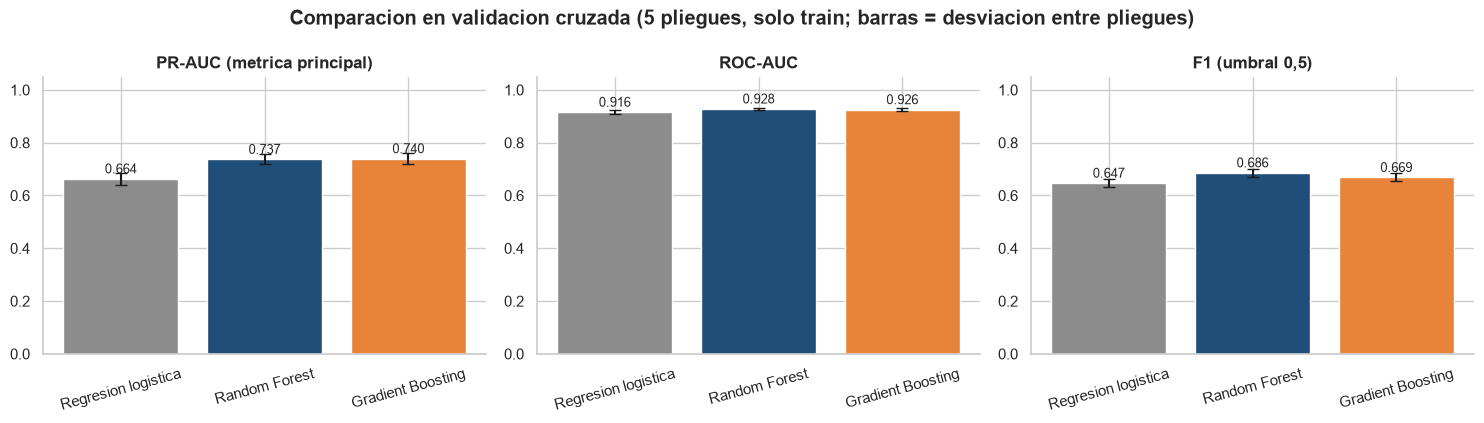

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
colores = [GRIS, AZUL, NARANJA]
for ax, m, tit in zip(axs, ['pr_auc', 'roc_auc', 'f1'], ['PR-AUC (metrica principal)', 'ROC-AUC', 'F1 (umbral 0,5)']):
    ax.bar(cv_tabla.index, cv_tabla[m], yerr=cv_tabla[m + '_std'], color=colores, capsize=4)
    for i, v in enumerate(cv_tabla[m]):
        ax.text(i, v + .02, f'{v:.3f}', ha='center', fontsize=9)
    ax.set_title(tit); ax.set_ylim(0, 1.05); ax.tick_params(axis='x', rotation=15)
plt.suptitle('Comparacion en validacion cruzada (5 pliegues, solo train; barras = desviacion entre pliegues)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG / '03_comparacion_cv.png', dpi=150, bbox_inches='tight')
plt.show()

**Comparación en validación cruzada (solo train)**

| Modelo | PR-AUC | ROC-AUC | F1 (umbral 0,5) | Recall | Precision |
|---|---|---|---|---|---|
| Regresión logística | 0,664 | 0,916 | 0,647 | 0,796 | 0,546 |
| Random Forest | 0,737 | 0,928 | 0,686 | 0,740 | 0,641 |
| Gradient Boosting | 0,740 | 0,926 | 0,669 | 0,782 | 0,585 |

- Los **modelos de árboles superan claramente a la regresión logística en PR-AUC (+0,07)**: hay **no linealidades e interacciones** que el modelo lineal no captura.
- **Random Forest y Gradient Boosting están empatados** (diferencia de 0,003 en PR-AUC, muy inferior a la desviación entre pliegues, ≈ 0,02): no se puede declarar un ganador solo con estos datos. El ajuste de hiperparámetros y el criterio fuera de muestra (siguiente sección) deciden.
- En ROC-AUC las tres diferencias parecen pequeñas (0,916–0,928): **la ROC-AUC es optimista con clases desbalanceadas**, la PR-AUC separa mejor a los modelos.